In [1]:
%run ./dataManipulation.ipynb

## Distribution of the mean pitch per audio clip

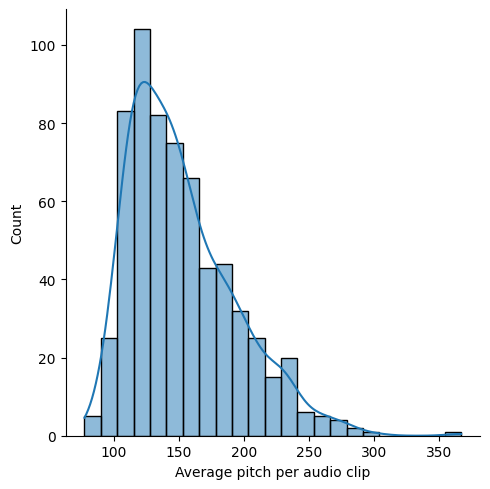

[7.091917143715987, 3.5332355718679572e-12]


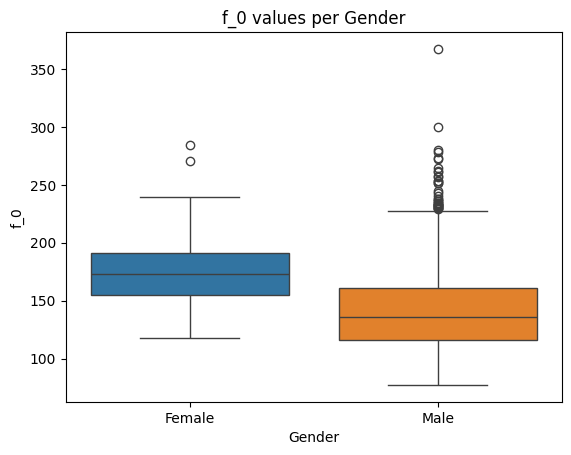

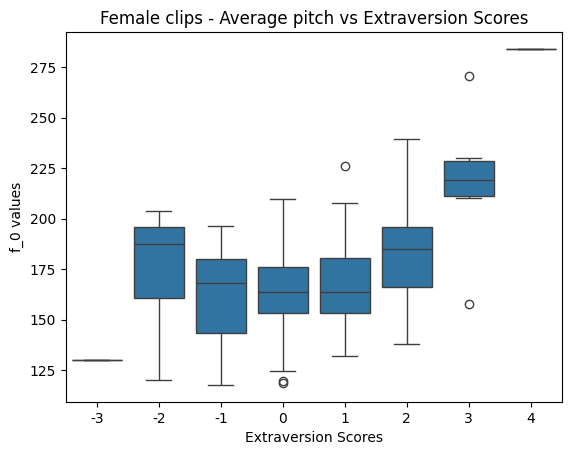

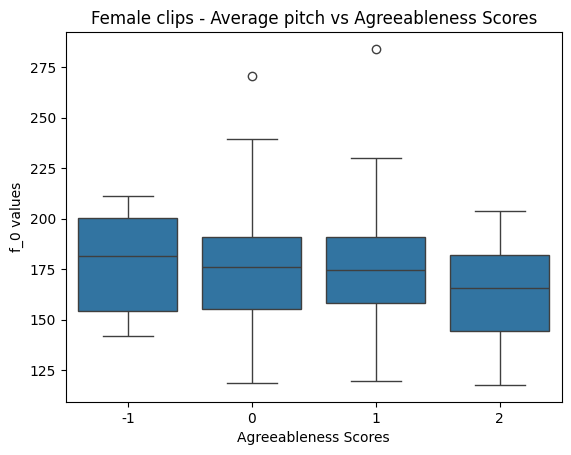

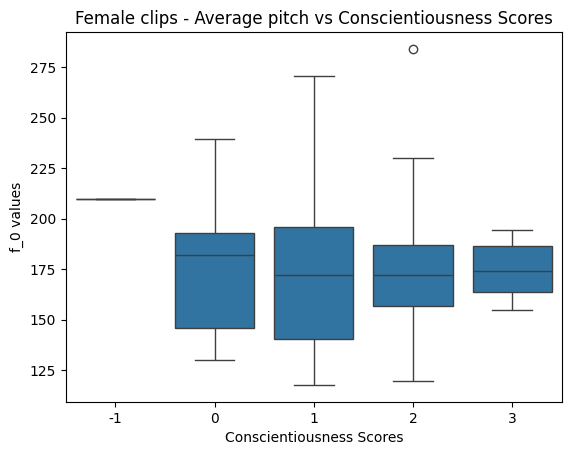

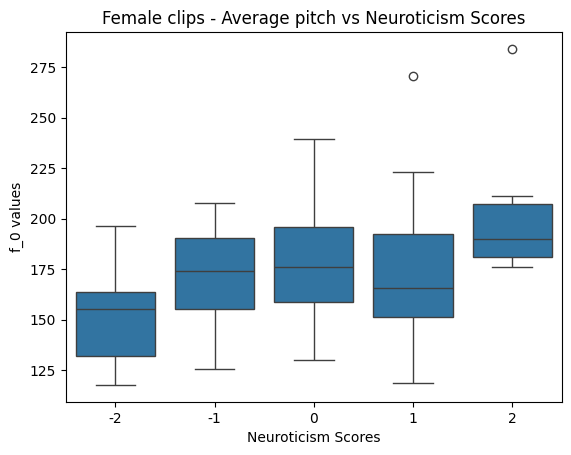

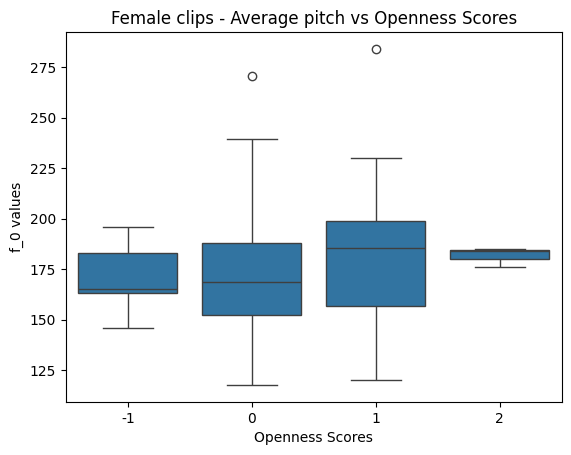

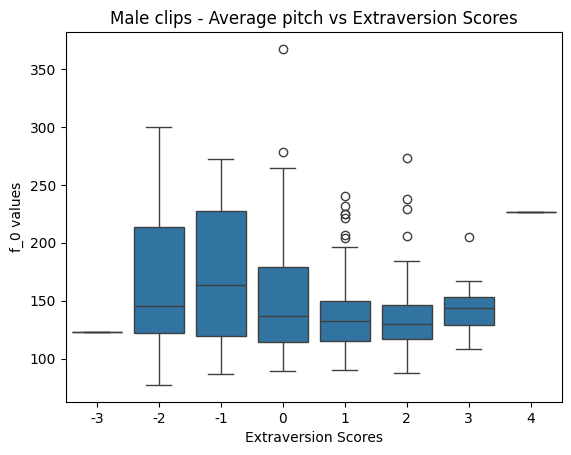

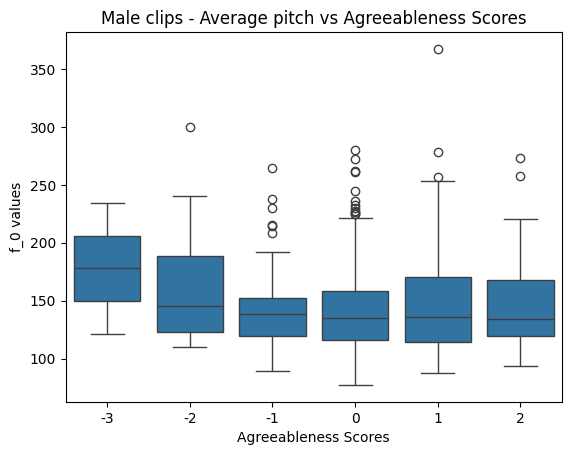

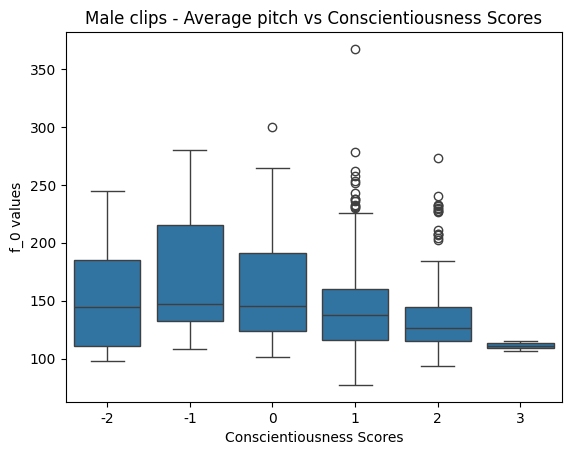

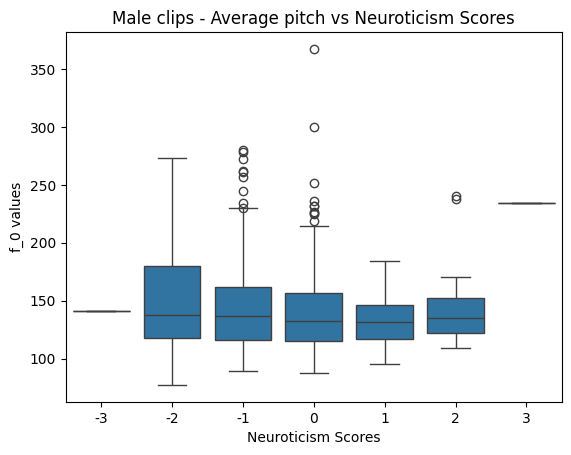

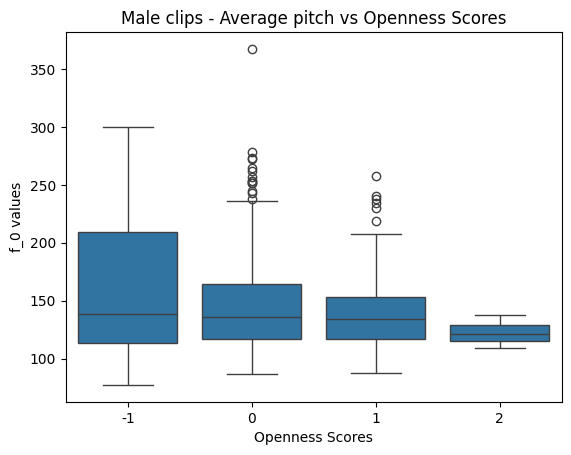

## Female Average pitch vs trait

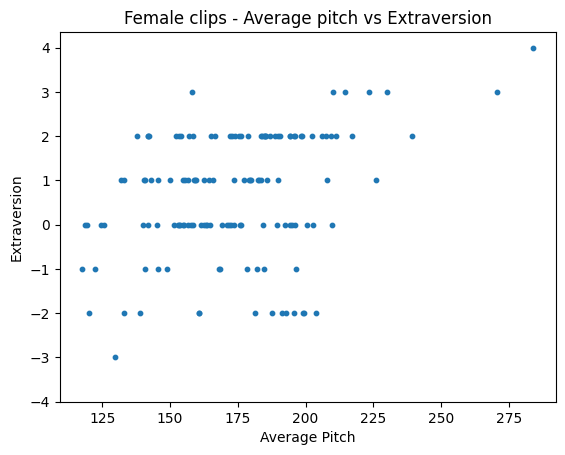

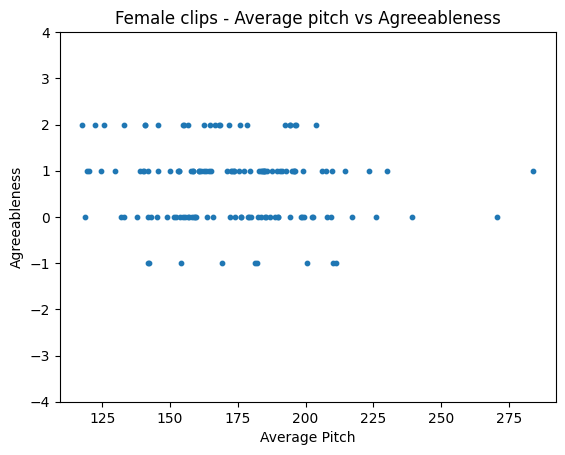

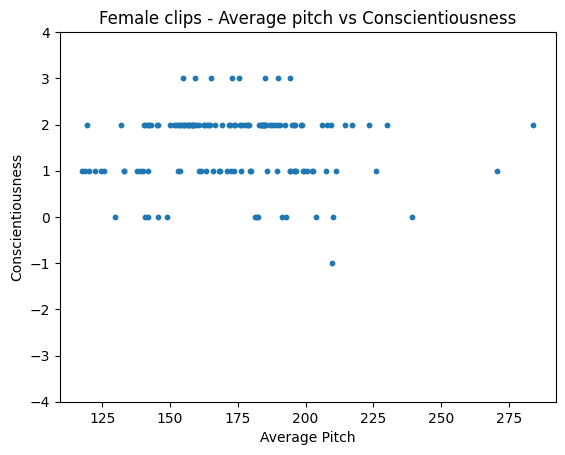

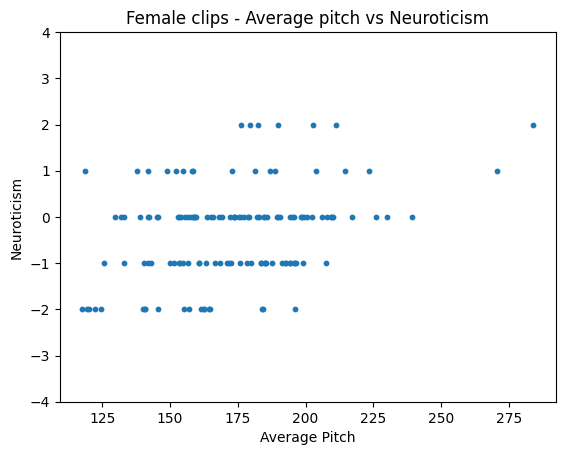

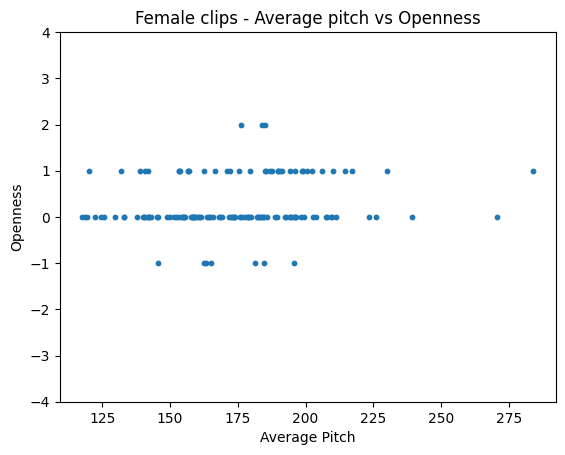

## Male Average pitch vs trait

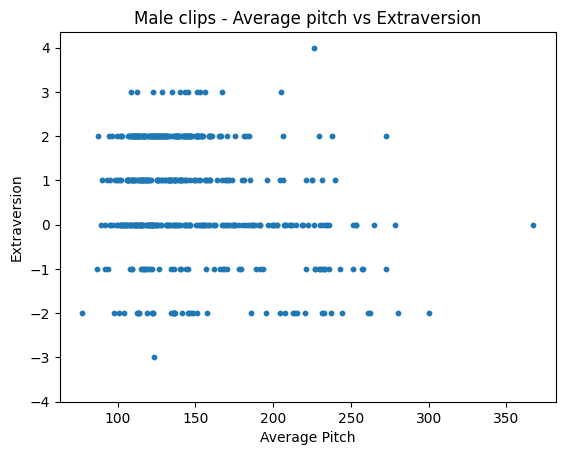

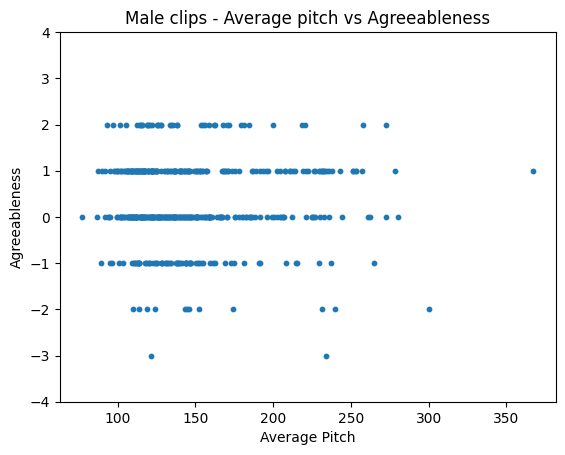

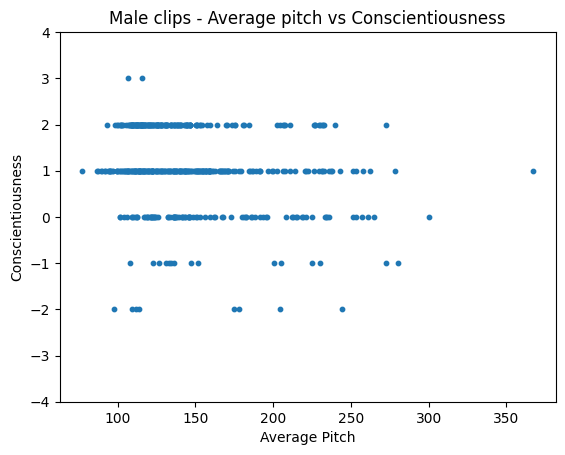

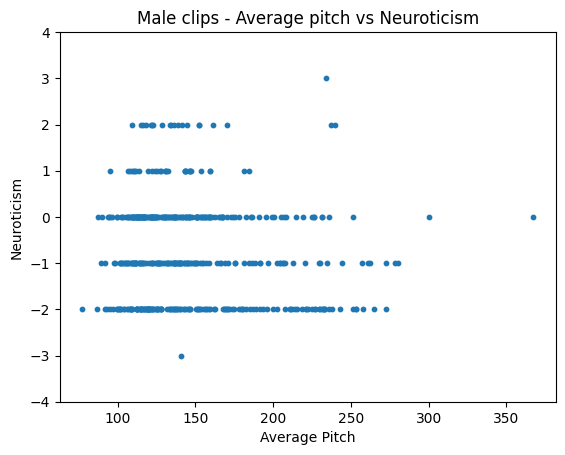

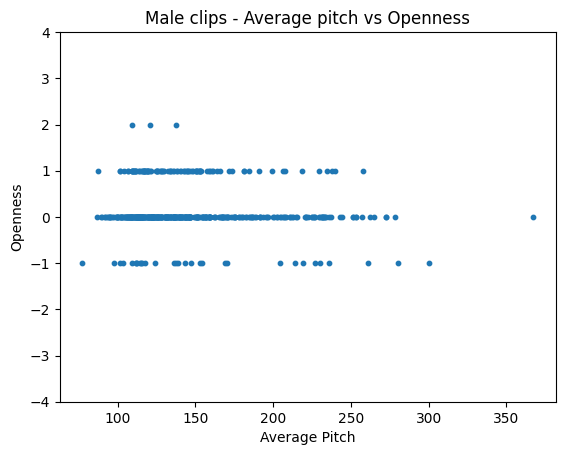

## Female Average Pitch

,rho,p
Extraversion,0.299961,0.000369
Agreeableness,-0.108466,0.207071
Conscientiousness,-0.008762,0.919055
Neuroticism,0.270054,0.001416
Openness,0.159689,0.062327


## Male Average Pitch

,rho,p
Extraversion,-0.166116,0.000188
Agreeableness,-0.00446,0.920685
Conscientiousness,-0.217335,0.000001
Neuroticism,-0.071829,0.108316
Openness,-0.040626,0.364172


In [2]:
%run ./audioCorrelations.ipynb

In [3]:
import seaborn as sns
from scipy import stats

from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


2024-02-21 23:37:11.141536: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
columns = ['clipID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender']
listOfGenders = np.array(metadata)[:,2]
unique_values, counts = np.unique(listOfGenders, return_counts=True)

## Class Imbalance

,Value,Frequency,Percentage
Male,0,503,78.59375
Female,1,137,21.40625


Text(0.5, 1.0, 'Frequency of Classes Male vs Female')

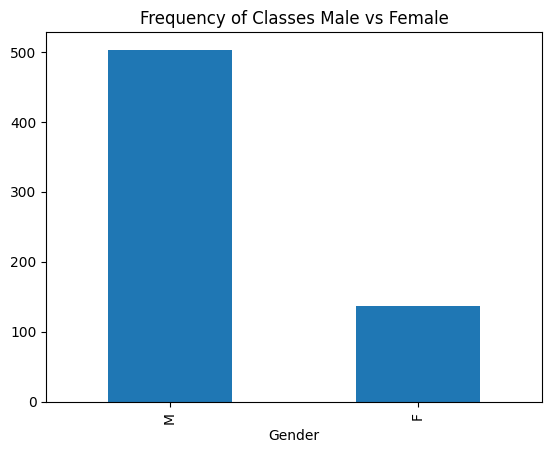

In [5]:
labelencoder=LabelEncoder()
y=to_categorical(labelencoder.fit_transform(listOfGenders))[:,0].astype(int)
# No of men vs no of women

valueCounts = pd.DataFrame(y).value_counts().reset_index()
valueCounts.columns = ['Value', 'Frequency']
valueCounts = valueCounts.rename(index={0: 'Male', 1: 'Female'})
totalClips = valueCounts['Frequency'].sum()
valueCounts['Percentage'] = (valueCounts['Frequency'] / totalClips) * 100
display(Markdown('## Class Imbalance'))
display(valueCounts)


array = np.concatenate((medianScoresPerClip(), listOfGenders.reshape(-1,1)), axis=1)
df = pd.DataFrame(array, columns=columns)
dfMale = df[df.Gender == 'M']
dfFemale = df[df.Gender == 'F']
df = pd.concat([dfMale, dfFemale])
ax = df.Gender.value_counts().plot(kind='bar')
ax.set_title('Frequency of Classes Male vs Female')

In [6]:
# Getting median scores per clip as the feature values
X = medianScoresPerClip()[:,1:]
newX = np.concatenate((np.array(metadata)[:,0:2], X, y.reshape(-1, 1)), axis=1)
data = pd.DataFrame(newX, columns=['clipID', 'speakerID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender'])
# print(data.iloc[0])

data = data[data['clipID'] != 'cut_feb2203-human-20']
data = data[data['clipID'] != 'cut_feb2803-human-13']

In [17]:
featureColumns = ['pitchAverage', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
features = mergedDfAv[featureColumns]
labels = data['Gender'].astype(int)
groups = data['speakerID']


In [25]:

# ALGORITHMS
scaler = StandardScaler().fit(features.loc[:,featureColumns])
features.loc[:,featureColumns] = scaler.transform(features.loc[:,featureColumns])


logisticReg = LogisticRegression(solver='liblinear',class_weight='balanced',C=0.1, penalty= 'l2')
Kneightbors = KNeighborsClassifier(n_neighbors=3, weights='distance')
randomForest = RandomForestClassifier(n_estimators=100, class_weight='balanced', max_depth=10)
decisionTree=DecisionTreeClassifier(class_weight='balanced', max_depth=10)
SVM = SVC(kernel='poly', C=6, degree=5)

n_splits = 7
kFold = StratifiedGroupKFold(n_splits=n_splits) 

def calculateResults(model, X, y):
    # Get info from input X, y
    # features = X.loc[:,featureColumns]
    # target= y.astype(int)

    f1Scores=[]
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]

    fold_assignments = np.zeros_like(X['speakerID'])
    for fold, (train_index, test_index) in enumerate(kFold.split(features, labels, groups=groups)):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = labels.iloc[train_index], labels.iloc[test_index]
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        f1Scores.append(f1_score(y_te, prediction))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))
    result = pd.DataFrame({'Average f1 score': np.mean(f1Scores), 'Total confusion matrix': ([confusionMatrixTotal])})
    return (result)


# CALLING FUNCTION FOR EVERY MODEL TO GET RESULT OF K FOLD
algorithmName = ["Logistic Regression", "Random Forest", "Decision Tree", "SVM", "K neighbours"]
algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]
final = pd.DataFrame()
for i in range (len(algorithms)):
    final = pd.concat([final, calculateResults(algorithms[i], data, target)])
final.index = algorithmName
display(final)

,Average f1 score,Total confusion matrix
Logistic Regression,0.287538,"[[230, 271], [69, 68]]"
Random Forest,0.204271,"[[435, 66], [114, 23]]"
Decision Tree,0.292594,"[[265, 236], [72, 65]]"
SVM,0.052445,"[[457, 44], [132, 5]]"
K neighbours,0.174093,"[[413, 88], [116, 21]]"


In [26]:
f1Scores = []
confusionMatrices =[]
for i in range (len(algorithms)):
    result = calculateResults(algorithms[i], data, target)
    f1Scores.append(result['Average f1 score'])
    confusionMatrices.append(result['Total confusion matrix'])

In [27]:

binomialTestResults = pd.DataFrame()
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatrices[i][0][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatrices[i][0][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatrices[i][0][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatrices[i][0][1][1]  #c0rrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    # values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    binomialTestResults = pd.concat([binomialTestResults,values])

binomialTestResults.rename(columns={0: 'f1 value for test set', 1: 'Binomial test p value'}, inplace=True)
binomialTestResults.index = algorithmName
display(binomialTestResults)

,f1 value for test set,Binomial test p value
Logistic Regression,0.287538,1.386659e-24
Random Forest,0.174043,1.071648e-02
Decision Tree,0.290160,4.511706e-14
SVM,0.052445,1.686911e-03
K neighbours,0.174093,4.516250e-01


In [48]:

train_set_df = pd.DataFrame(columns=['F1 Score', 'Confusion Matrix'])
test_results_df = pd.DataFrame(columns=['F1 Score', 'Confusion Matrix'])

groupSplit = GroupShuffleSplit(n_splits=1, test_size=0.3)

for train_index, test_index in groupSplit.split(features, labels, groups=groups):
    X_train, X_test = features.iloc[train_index], features.iloc[test_index]
    y_train, y_test = labels.iloc[train_index], labels.iloc[test_index]
    groups_train, groups_test = groups.iloc[train_index], groups.iloc[test_index]

scaler = StandardScaler().fit(X_train.loc[:,featureColumns])
X_train.loc[:,featureColumns] = scaler.transform(X_train.loc[:,featureColumns])
X_test.loc[:,featureColumns] = scaler.transform(X_test.loc[:,featureColumns])

models = {
    'Logistic regression': (LogisticRegression(class_weight='balanced'), {'C': [0.1, 1, 10],  'penalty': ['l2']}),
    'Random forest': (RandomForestClassifier(class_weight='balanced'), {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20, 30]}),
    'Decision tree': (DecisionTreeClassifier(class_weight='balanced'), {'max_depth': [None, 10, 20, 30]}),
    'K neighbours': (KNeighborsClassifier(weights='distance'), {'n_neighbors': [3, 5, 7, 9]}),
    'SVM': (SVC(), {'C': [0.1, 1, 5, 10], 'kernel': ['rbf','linear','poly'], 'degree': [2, 3, 5]})
}


for modelName, (model, parameters) in models.items():
    train_confusion_matrix = np.zeros((2, 2))
    
    train_f1 = []
    test_f1 = []
    
    kFold = StratifiedGroupKFold(n_splits=5)

    for fold, (train_index, val_index) in enumerate(kFold.split(X_train, y_train, groups=groups_train)):
        X_train_fold, X_val_fold = X_train.iloc[train_index], X_train.iloc[val_index]
        y_train_fold, y_val_fold = y_train.iloc[train_index], y_train.iloc[val_index]

        gridSearchCV = GridSearchCV(model, parameters, cv=StratifiedGroupKFold(n_splits=5), scoring='f1',n_jobs=-1, verbose=0)
        gridSearchCV.fit(X_train_fold, y_train_fold, groups=groups_train.iloc[train_index])

        prediction_val = gridSearchCV.predict(X_val_fold)
        train_confusion_matrix += confusion_matrix(y_val_fold, prediction_val)
        train_f1.append(f1_score(y_val_fold, prediction_val))

    print("Train set - ", modelName)
    print(train_confusion_matrix)
    print(np.mean(train_f1))
    
    prediction_test = gridSearchCV.predict(X_test)
    confusion_matrix_test = confusion_matrix(y_test, prediction_test)
    f1Score = f1_score(y_test, prediction_test)
    test_f1.append(f1Score)

    
    print("Test set - ", modelName)
    print(confusion_matrix_test)
    print(f1_score(y_test, prediction_test))

    train_set_df.loc[modelName] = [np.mean(train_f1), train_confusion_matrix]
    test_results_df.loc[modelName] = [test_f1, confusion_matrix_test]
    
    print(f"{modelName} optimal Parameters: {gridSearchCV.best_params_}")


print("\nTraining Set")
display(train_set_df)
print("\nTest Set")
display(test_results_df)


Train set -  Logistic regression
[[161. 180.]
 [ 56.  54.]]
0.3108032286232955
Test set -  Logistic regression
[[76 84]
 [11 16]]
0.25196850393700787
Logistic regression optimal Parameters: {'C': 0.1, 'penalty': 'l2'}
Train set -  Random forest
[[274.  67.]
 [ 87.  23.]]
0.22779792291278392
Test set -  Random forest
[[116  44]
 [ 18   9]]
0.22499999999999998
Random forest optimal Parameters: {'max_depth': 10, 'n_estimators': 100}
Train set -  Decision tree
[[178. 163.]
 [ 59.  51.]]
0.31079891843904595
Test set -  Decision tree
[[86 74]
 [17 10]]
0.18018018018018017
Decision tree optimal Parameters: {'max_depth': 10}
Train set -  K neighbours
[[282.  59.]
 [ 94.  16.]]
0.17259246130213873
Test set -  K neighbours
[[127  33]
 [ 23   4]]
0.125
K neighbours optimal Parameters: {'n_neighbors': 3}
Train set -  SVM
[[306.  35.]
 [104.   6.]]
0.0751800356506239
Test set -  SVM
[[148  12]
 [ 26   1]]
0.05
SVM optimal Parameters: {'C': 5, 'degree': 5, 'kernel': 'poly'}

Training Set


,F1 Score,Confusion Matrix
Logistic regression,0.310803,"[[161.0, 180.0], [56.0, 54.0]]"
Random forest,0.227798,"[[274.0, 67.0], [87.0, 23.0]]"
Decision tree,0.310799,"[[178.0, 163.0], [59.0, 51.0]]"
K neighbours,0.172592,"[[282.0, 59.0], [94.0, 16.0]]"
SVM,0.075180,"[[306.0, 35.0], [104.0, 6.0]]"



Test Set


,F1 Score,Confusion Matrix
Logistic regression,[0.25196850393700787],"[[76, 84], [11, 16]]"
Random forest,[0.22499999999999998],"[[116, 44], [18, 9]]"
Decision tree,[0.18018018018018017],"[[86, 74], [17, 10]]"
K neighbours,[0.125],"[[127, 33], [23, 4]]"
SVM,[0.05],"[[148, 12], [26, 1]]"


In [47]:
binomialTestResults = pd.DataFrame()

confusionMatrices = test_results_df['Confusion Matrix']
print(confusionMatrices)
f1Scores = test_results_df['F1 Score']

for i in range(4):
    testSetSize = y_test.size
    trueNeg = confusionMatrices.iloc[i][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatrices.iloc[i][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatrices.iloc[i][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatrices.iloc[i][1][1]  #cozrrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[f1Scores.iloc[i], result.pvalue]])
    # values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    binomialTestResults = pd.concat([binomialTestResults,values])

binomialTestResults.rename(columns={0: 'f1 value for test set', 1: 'Binomial test p value'}, inplace=True)
binomialTestResults.index = test_results_df.index
display(binomialTestResults)

Logistic regression    [[70, 77], [18, 13]]
Decision tree          [[68, 79], [19, 12]]
Random forest          [[124, 23], [26, 5]]
K neighbours           [[125, 22], [26, 5]]
Name: Confusion Matrix, dtype: object


,f1 value for test set,Binomial test p value
Logistic regression,[0.21487603305785122],7.215522e-08
Decision tree,[0.19672131147540986],6.222414e-09
Random forest,[0.1694915254237288],9.546500e-02
K neighbours,[0.17241379310344826],6.774511e-02
